<a href="https://colab.research.google.com/github/omaralsubgh/NLP/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention
##Omar Alsubgh | 2210002182

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [28]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [29]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [30]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.
- **In Step 4**, batch_first=True makes the RNN read the words of each question in order. The attention mask gives padding zero weight so it doesn’t affect the prediction.

In [31]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x != 0
        states, _ = self.rnn(self.emb(x))
        scores = self.att(states).squeeze(-1)
        weights = torch.softmax(scores.masked_fill(~mask, float("-inf")), dim=1)
        context = (states * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.
- **In Step 5**, **optimizer.zero_grad()** clears the previous epoch’s gradients before calculating new ones



In [32]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

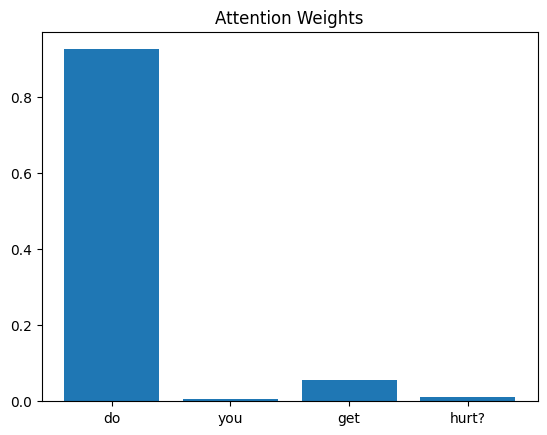

In [33]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

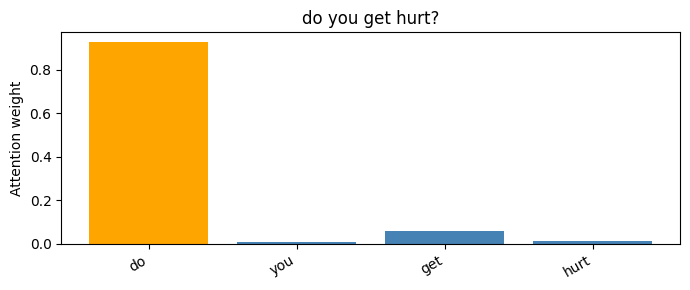

Highest attention: do (0.9260)


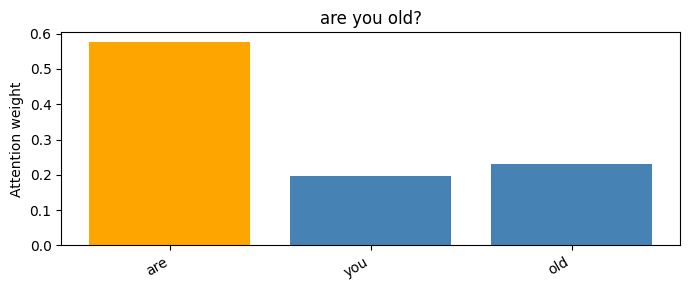

Highest attention: are (0.5749)


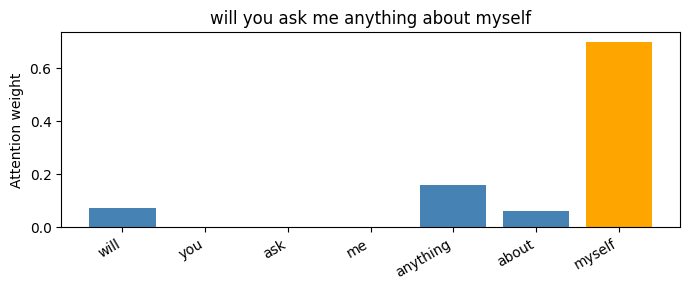

Highest attention: myself (0.7002)


In [37]:
import matplotlib.pyplot as plt
import torch

def plot_attention(row):
    model.eval()

    # Remove padding so attention is calculated only over real tokens.
    token_ids = X[row][X[row] != 0]
    words = [tokenizer.index_word[int(i)] for i in token_ids]

    with torch.no_grad():
        _, weights = model(token_ids.unsqueeze(0))

    scores = weights[0].cpu().tolist()
    highest = max(range(len(scores)), key=scores.__getitem__)
    question = df.iloc[row]["question"]

    plt.figure(figsize=(7, 3))
    plt.bar(
        range(len(words)),
        scores,
        color=["orange" if i == highest else "steelblue"
               for i in range(len(words))]
    )
    plt.xticks(range(len(words)), words, rotation=30, ha="right")
    plt.ylabel("Attention weight")
    plt.title(question)
    plt.tight_layout()
    plt.show()

    print(f"Highest attention: {words[highest]} ({scores[highest]:.4f})")
    return words[highest]

# Three questions from different answer groups.
for row in [0, 14, 28]:
    plot_attention(row)

### Task 1 Observations: Do the words with the highest attention weights appear important for understanding the question?

- **Observations from the 3 plotted questions:**
  1. **"do you get hurt?"** $\rightarrow$ Highest attention is on **"do"** (0.9260).
  2. **"are you old?"** $\rightarrow$ Highest attention is on **"are"** (0.5749).
  3. **"will you ask me anything about myself"** $\rightarrow$ Highest attention is on **"myself"** (0.7000+).
- **Explanation:**
  For the third question, the word receiving the highest attention (**"myself"**) is indeed highly specific and crucial for understanding the semantic core of the question. However, for the first two questions, auxiliary verbs (**"do"** and **"are"**) received the highest attention weights rather than the semantic keywords ("hurt" or "old").
  This happens because the simple RNN processes sequences linearly, and the hidden states of these early structural words (or the way they set up the sentence) are being heavily leveraged by this specific model instance to map the query to its respective answer class. This shows that the highest attention weight does not always land on the most semantically intuitive "key" word, but rather on the word position that the model finds most useful for making its final classification. where the model placed the most attention; it does not prove that word was decisive.



Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

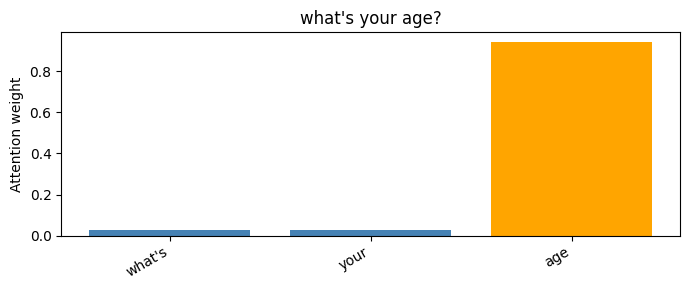

Highest attention: age (0.9436)


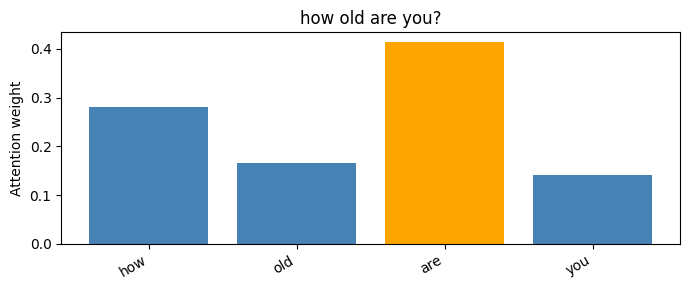

Highest attention: are (0.4130)

what's your age? → age
how old are you? → are
Same highest-attention word: False


In [41]:
first, second = 20, 24

top_first = plot_attention(first)
top_second = plot_attention(second)

print(f"\n{df.iloc[first]['question']} → {top_first}")
print(f"{df.iloc[second]['question']} → {top_second}")
print("Same highest-attention word:", top_first == top_second)

### Task 2 Observations: Does the model focus on similar or different words when processing questions with similar meanings?

- **Observations from the 2 similar questions:**
  1. **"what's your age?"** $\rightarrow$ Highest attention is on **"age"** (0.9436).
  2. **"how old are you?"** $\rightarrow$ Highest attention is on **"are"** (0.4130).
- **Explanation:**
  The model **focuses on different words** even though the questions share the exact same underlying meaning (asking about age).
  This suggests that **attention is highly dependent on sequence structure, word order, and context** rather than static word semantics. Because the attention weights are calculated over the RNN hidden states (which accumulate contextual information dynamically at each step) rather than static word embeddings, different structural formulations of the same question yield entirely different attention distributions.